# Qubit hamiltonian factory

In this notebook we try to write a code for transition between OpenFermion generated hamiltonians, and those ones, which are used by C++ code

## Basic imports

In [241]:
%matplotlib notebook
import numpy as np

import os

from matplotlib import pyplot as plt

import openfermion

import pickle

from openfermion.hamiltonians import MolecularData
from openfermionpsi4 import run_psi4
from openfermion.transforms import get_fermion_operator, bravyi_kitaev, jordan_wigner, symmetry_conserving_bravyi_kitaev
from openfermion.utils import geometry_from_pubchem

## Dumping functions

In [242]:
def save_hamiltonian_to_pauli_strings(t_hamiltonian,
                                      t_path,
                                      t_filename):
    if not os.path.exists(t_path):
        os.makedirs(t_path)
    qubit_num = max([op_tuple[len(op_tuple)-1][0] + 1 for op_tuple in t_hamiltonian.terms if len(op_tuple) > 0])
    with open(os.path.join(t_path, t_filename), 'w') as f:
        f.write(f'{qubit_num}\n')
        for term in sorted(t_hamiltonian.terms):
            f.write(f'{term_to_pauli_string(term, qubit_num)}\t{t_hamiltonian.terms[term].real}\n')            

## Utility functions

In [243]:
def decimal_point_to_underscore(t_x):
    return f'{t_x:.3f}'.rstrip('0').replace('.', '_')

In [244]:
def underscore_to_decimal_point(t_x):
    return float(t_x.replace('_', '.'))

In [245]:
def term_to_pauli_string(t_term, t_qubit_num):
    pauli_string = ['I'] * t_qubit_num
    for qubit_idx, op in t_term:
        pauli_string[qubit_idx] = op
        
    return ''.join(pauli_string)

In [252]:
def int_to_bit_string(t_x, t_bit_num=None):
    result = ''
    if t_bit_num is None:
        while t_x:
            if t_x & 1:
                result += '1'
            else:
                result += '0'
            t_x >>= 1
    else:
        for idx in range(t_bit_num):
            if t_x & 1:
                result += '1'
            else:
                result += '0'
            t_x >>= 1
        
    return result[::-1]

In [264]:
#bond_lengths = np.arange(0.1, 6.0, 0.1)
bond_lengths = [1.547]
print(bond_lengths)

[1.547]


## Generating hamiltonians

In [268]:
umbrella_dir = '../molecules'
molecule_name = 'LiH_equilibrium_reduced'

molecule_dir = os.path.join(umbrella_dir, molecule_name)
if not os.path.exists(molecule_dir):
    os.makedirs(molecule_dir)
    
hamiltonians_dir = os.path.join(molecule_dir, 'hamiltonians')
if not os.path.exists(hamiltonians_dir):
    os.makedirs(hamiltonians_dir)
    
solutions_dir = os.path.join(molecule_dir, 'solutionz')
if not os.path.exists(solutions_dir):
    os.makedirs(solutions_dir)

hdf5_dir = os.path.join(molecule_dir, 'hdf5')
if not os.path.exists(hdf5_dir):
    os.makedirs(hdf5_dir)    

In [269]:
method_to_name = {
    'HF': 'Hartree-Fock',
    'MP2': 'MP2',
    'FCI': 'FCI',
    'NNQS_EXACT': 'NNQS, exact',
    'NNQS_APPROX': 'NNQS, approx'
}
method_to_attr = {
    'HF': 'hf_energy',
    'MP2': 'mp2_energy',
    'FCI': 'fci_energy'
}

### Generating hamiltonians for linear molecules

In [ ]:
for bond_length in bond_lengths:
    #bond_length_label = f'{bond_length:.1f}'
    bond_length_label = f'{bond_length}'
    print(f'Bond length: {bond_length_label}')
    
    bond_dir = os.path.join(solutions_dir, bond_length_label)
    if not os.path.exists(bond_dir):
        os.makedirs(bond_dir)
    
    geometry = [['Li', [0, 0, 0]],
                ['H', [0, 0, bond_length]]]
    basis = 'sto-3g'
    multiplicity = 1
    charge = 0
    
    molecule = MolecularData(geometry,
                             basis,
                             multiplicity,
                             charge,
                             filename=os.path.join(hdf5_dir, bond_length_label))
    
    if os.path.exists(f'{molecule.filename}.hdf5'):
        print(f'.hdf5 successfully found, loading the molecule...')
        molecule.load()
        print(f'The molecule was successfully loaded!')
    else:
        print(f'Can\'t find .hdf5 for data, starting psi4 calculations')
        molecule = run_psi4(molecule,
                            run_mp2=True,
                            run_cisd=True,
                            run_ccsd=True,
                            run_fci=True)
        print(f'Psi4 calculations are done!')
    
    fermion_operator = get_fermion_operator(molecule.get_molecular_hamiltonian())
#     qubit_hamiltonian = jordan_wigner(get_fermion_operator(molecule.get_molecular_hamiltonian()))
    qubit_hamiltonian = symmetry_conserving_bravyi_kitaev(fermion_operator, 12, 2)
    save_hamiltonian_to_pauli_strings(qubit_hamiltonian,
                                      hamiltonians_dir,
                                      bond_length_label)
    for method in method_to_attr:
        print(f'{method_to_name[method]} energy: {getattr(molecule, method_to_attr[method])}')
        method_output_file = os.path.join(bond_dir, f'ground_energy_{method}.txt')
        #if not os.path.exists(method_output_file):
        with open(method_output_file, 'w') as f:
            f.write(f'{getattr(molecule, method_to_attr[method])}')
            
    print('\n')

Bond length: 1.547
Can't find .hdf5 for data, starting psi4 calculations


### Generating geometries for non-linear molecules

In [22]:
geometry = geometry_from_pubchem('H2O')
print(geometry)

[('O', (0, 0, 0)), ('H', (0.2774, 0.8929, 0.2544)), ('H', (0.6068, -0.2383, -0.7169))]


In [23]:
print(f'{geometry}')

[('O', (0, 0, 0)), ('H', (0.2774, 0.8929, 0.2544)), ('H', (0.6068, -0.2383, -0.7169))]


In [351]:
print(f'Geometry: {geometry}')
geometry_dir = os.path.join(solutions_dir, f'pubchem')
if not os.path.exists(geometry_dir):
    os.makedirs(geometry_dir)
    
basis = 'sto-3g'
multiplicity = 1
charge = 0

molecule = MolecularData(geometry,
                         basis,
                         multiplicity,
                         charge,
                         filename=os.path.join(hdf5_dir, f'pubchem'))

if os.path.exists(f'{molecule.filename}.hdf5'):
    print(f'.hdf5 successfully found, loading the molecule...')
    molecule.load()
    print(f'The molecule was successfully loaded!')
else:
    print(f'Can\'t find .hdf5 for data, starting psi4 calculations')
    molecule = run_psi4(molecule,
                        run_mp2=True,
                        run_cisd=True,
                        run_ccsd=True,
                        run_fci=True)
    print(f'Psi4 calculations are done!')

fermion_operator = get_fermion_operator(molecule.get_molecular_hamiltonian())
qubit_hamiltonian = jordan_wigner(get_fermion_operator(molecule.get_molecular_hamiltonian()))
save_hamiltonian_to_pauli_strings(qubit_hamiltonian,
                                  hamiltonians_dir,
                                  f'pubchem')
for method in method_to_attr:
    print(f'{method_to_name[method]} energy: {getattr(molecule, method_to_attr[method])}')
    method_output_file = os.path.join(geometry_dir, f'{method}.txt')
    if not os.path.exists(method_output_file):
        with open(method_output_file, 'w') as f:
            f.write(f'{getattr(molecule, method_to_attr[method])}')

print('\n')

Geometry: [['H', [0, 0, 0]], ['H', [0, 0, 0.1]]]
Can't find .hdf5 for data, starting psi4 calculations
Psi4 calculations are done!
Hartree-Fock energy: 2.715887390825488
MP2 energy: 2.71125960618545
FCI energy: 2.7099607683997733




# Plotting the results

In [212]:
molecule_name = 'H2_reduced'

In [213]:
r_methods = ['simcim_cpp_k_local']
non_r_methods = ['HF', 'FCI']
methods =  r_methods + non_r_methods

In [214]:
solutions_prefixes = {
    method: os.path.join(f'../', f'molecules', molecule_name, f'solutionz')
    for method in methods
}

In [215]:
path_to_solutions = {
    method: solutions_prefixes[method]
    for method in methods
}

In [216]:
r_nums = [1, 2, 3, 16, 20]
outputs = {
    method: {}
    for method in methods
}

In [217]:
for method in methods:
    for dist_dir_name in os.listdir(path_to_solutions[method]):
        if dist_dir_name != 'pubchem':
            for r_num in r_nums:
                cur_dir = os.path.join(path_to_solutions[method], dist_dir_name)
                cur_dict = outputs[method]
                if os.path.exists(os.path.join(cur_dir, f'r={r_num}', f'ground_energy_{method}.txt')):
                    cur_dir = os.path.join(cur_dir, f'r={r_num}')
                    if r_num not in outputs[method]:
                        outputs[method][r_num] = {}
                    cur_dict = outputs[method][r_num]

                dist = float(dist_dir_name)
                path_to_solution = os.path.join(cur_dir, f'ground_energy_{method}.txt')
                if os.path.exists(path_to_solution):
                    with open(path_to_solution, 'r') as f:
                        a = f.read()
                        try:
                            a = float(a)
                        except ValueError:
                            pass
                        else:
                            cur_dict[dist] = a

In [218]:
if molecule_name == 'LiH_psi4_reduced':
    outputs['simcim_cpp_k_local'][2].pop(1.95)

In [219]:
outputs_chem_acc = {}

for method in r_methods:
    outputs_chem_acc[method] = {}
    for r_num in outputs[method]:
        outputs_chem_acc[method][r_num] = {}
        for dist in outputs[method][r_num]:
            if dist in outputs['FCI']:
                outputs_chem_acc[method][r_num][dist] = outputs[method][r_num][dist] - outputs['FCI'][dist]
                
for method in non_r_methods:
    outputs_chem_acc[method] = {}
    for dist in outputs[method]:
        if dist in outputs['FCI']:
            outputs_chem_acc[method][dist] = outputs[method][dist] - outputs['FCI'][dist]

In [220]:
outputs_x = {
    method: np.asarray(sorted(outputs[method].keys()))
        for method in non_r_methods    
}
outputs_x.update({
    method: {
        r_num: np.asarray(sorted(outputs[method][r_num].keys()))
        for r_num in outputs[method]
    }
    for method in r_methods
})

In [221]:
outputs_y = {
    method: np.asarray([outputs[method][dist] for dist in outputs_x[method]])
        for method in non_r_methods    
}
outputs_y.update({
    method: {
        r_num: np.asarray([outputs[method][r_num][dist] for dist in outputs_x[method][r_num]])
        for r_num in outputs[method]
    }
    for method in r_methods
})

In [222]:
with open(f'{molecule_name}_x.pickle', 'wb') as handle:
    pickle.dump(outputs_x, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [223]:
with open(f'{molecule_name}_y.pickle', 'wb') as handle:
    pickle.dump(outputs_y, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [224]:
outputs_chem_acc_x = {
    method: np.asarray(sorted(outputs_chem_acc[method].keys()))
        for method in non_r_methods    
}
outputs_chem_acc_x.update({
    method: {
        r_num: np.asarray(sorted(outputs_chem_acc[method][r_num].keys()))
        for r_num in outputs_chem_acc[method]
    }
    for method in r_methods
})
with open(f'{molecule_name}_chem_acc_x.pickle', 'wb') as handle:
    pickle.dump(outputs_chem_acc_x, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [225]:
outputs_chem_acc_y = {
    method: np.asarray([outputs_chem_acc[method][dist] for dist in outputs_chem_acc_x[method]])
        for method in non_r_methods    
}
outputs_chem_acc_y.update({
    method: {
        r_num: np.asarray([outputs_chem_acc[method][r_num][dist] for dist in outputs_chem_acc_x[method][r_num]])
        for r_num in outputs_chem_acc[method]
    }
    for method in r_methods
})
with open(f'{molecule_name}_chem_acc_y.pickle', 'wb') as handle:
    pickle.dump(outputs_chem_acc_y, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [226]:
molecule_name_to_molecule = {
    'H2_reduced': 'hydrogen',
    'hydrogen': 'hydrogen',
    'hydrogen_psi4': 'hydrogen',
    'hydrogen_hybrid': 'hydrogen',
    'hydrogen_cpp': 'hydrogen',
    'helium_2': 'helium_2',
    'LiH_psi4_reduced': 'LiH_psi4_reduced',
}
method_to_label = {
    'brute_force': 'Brute force',
    'simcim': 'SimCIM',
    'simcim_cpp': 'SimCIM',
    'simcim_python_k_local': 'SimCIM Python k-local',
    'simcim_cpp_k_local': 'SimCIM k-local',
    'exact': 'Exact ground energy',
    'HF': 'HF',
    'FCI': 'FCI',
}
method_to_color = {
    'brute_force': 'xkcd:bright blue',
    'simcim': 'xkcd:bright blue',
    'simcim_cpp':  'xkcd:peach',
    'simcim_python_k_local': 'xkcd:peach',
    'simcim_cpp_k_local': 'xkcd:aquamarine',
    'exact': 'xkcd:light red',
    'HF': 'black',
    'FCI': 'red',
}
method_to_ms = {
    'simcim': 7,
    'simcim_cpp': 7,
    'simcim_python_k_local': 7,
    'brute_force': 5,
    'exact': 4,
}
method_to_linewidth = {
    'brute_force': 3,
    'simcim': 3,
    'simcim_cpp': 3.5,
    'simcim_cpp_k_local': 3.75,
    'exact': 4,
}
r_num_to_linestyle = {
    25: '--',
    20: '-',
    16: '-',
    15: '-',
    4: '-',
    3: ':',
    2: '--',
    1: ':',
}
molecule_name_to_title = {
    'hydrogen': f'$H_2$',
    'helium_2': f'$He_2$',
    'LiH_psi4_reduced': f'LiH',
}
molecule_name_to_xlim = {
    'hydrogen': (0.0, 6.0),
    'helium_2': (0.5, 4.5),
    'LiH_psi4_reduced': (0.5, 5.0),
}
molecule_name_to_ylim = {
    'hydrogen': (-1.2, 0.4),
    'helium_2': (-6.0, 0.0),
    'LiH_psi4_reduced': (-8.0, -5.0),
}
figsize = 10
linewidth = 3
angstrom_to_au = 1.0 / 0.52
fs = 20

<IPython.core.display.Javascript object>


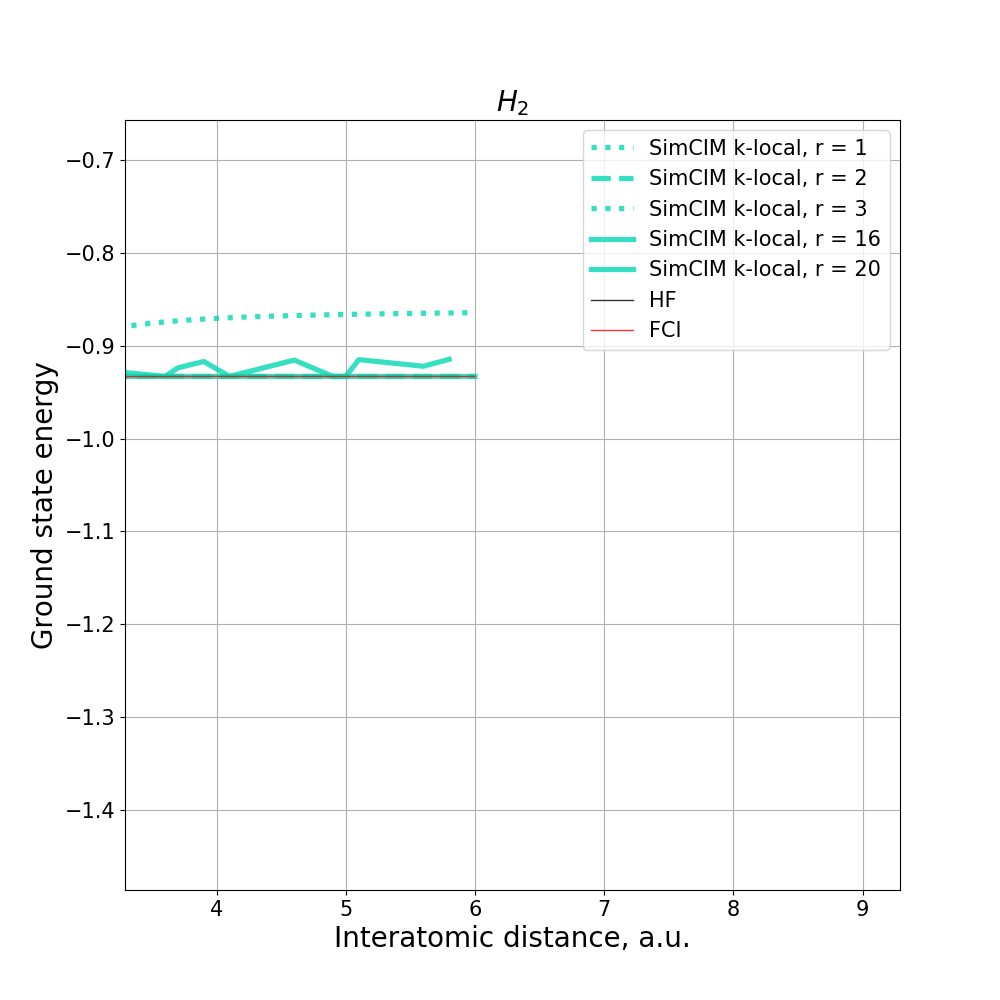

In [227]:
fig, ax = plt.subplots()
fig.set_figwidth(figsize)
fig.set_figheight(figsize)
ax.grid()
    
for r_num in r_nums:
    for method in r_methods:
        if method != 'exact':
            ax.plot(outputs_x[method][r_num],# * angstrom_to_au,
                outputs_y[method][r_num],
                label=method_to_label[method] + f', r = {r_num}',
                linewidth=method_to_linewidth[method],
                linestyle=r_num_to_linestyle[r_num],
                #linestyle='',
                #marker='o',
                #ms=method_to_ms[method],
                color=method_to_color[method],
                alpha=0.8)
#             filename = f'{molecule_name}_{method}_{r_num}'
for method in non_r_methods:
    if method != 'exact':
        ax.plot(outputs_x[method],# * angstrom_to_au,
            outputs_y[method],
            label=method_to_label[method],
            linewidth=1,
            linestyle='-',
            #linestyle='',
            #marker='o',
            #ms=method_to_ms[method],
            color=method_to_color[method],
            alpha=0.8)
# ax.plot(outputs_x['FCI'] * angstrom_to_au,
#     outputs_y['FCI'] + 1.6e-3,
#     label='Chemical accuracy FCI',
#     linewidth=1,
#     linestyle='-',
#     #linestyle='',
#     #marker='o',
#     #ms=method_to_ms[method],
#     color='blue',
#     alpha=0.8)
#         filename = f'{molecule_name}_{method}_{r_num}'
#             x_y_data = np.asarray([outputs_x[method][r_num] * angstrom_to_au,
#                                    outputs_y[method][r_num]])
#             np.savetxt(filename, x_y_data)
    
# ax.plot(outputs_x['exact'][r_num] * angstrom_to_au,
#                 outputs_y['exact'][r_num],
#                 label=method_to_label['exact'],
#                 linewidth=method_to_linewidth[method],
#                 linestyle='-',
#                 #linestyle='',
#                 #marker='o',
#                 #ms=method_to_ms['exact'],
#                 color=method_to_color['exact'],
#                 alpha=0.9)
# method='exact'
# filename = f'{molecule_name}_{method}'
# x_y_data = np.asarray([outputs_x[method][1] * angstrom_to_au,
#                        outputs_y[method][1]])
# np.savetxt(filename, x_y_data)

ax.set_title(molecule_name_to_title.get(molecule_name_to_molecule[molecule_name], None), fontsize=fs)
ax.legend(loc='best', fontsize=fs-5)
ax.set_xlabel('Interatomic distance, a.u.', fontsize=fs)
for tick in ax.xaxis.get_major_ticks():
    tick.label.set_fontsize(fs-5) 
ax.set_ylabel('Ground state energy', fontsize=fs)
for tick in ax.yaxis.get_major_ticks():
    tick.label.set_fontsize(fs-5) 
#ax.set_yscale('symlog', linthreshy=0.05, subsy=[2, 3, 4, 5, 6, 7, 8, 9])
ax.set_xlim(molecule_name_to_xlim.get(molecule_name_to_molecule[molecule_name], (None, None)))
#ax.set_ylim(molecule_name_to_ylim.get(molecule_name_to_molecule[molecule_name], (None, None)))
ax.set_ylim((None, -0.5))
fig.savefig('LiH_psi4_reduced.png')


<IPython.core.display.Javascript object>


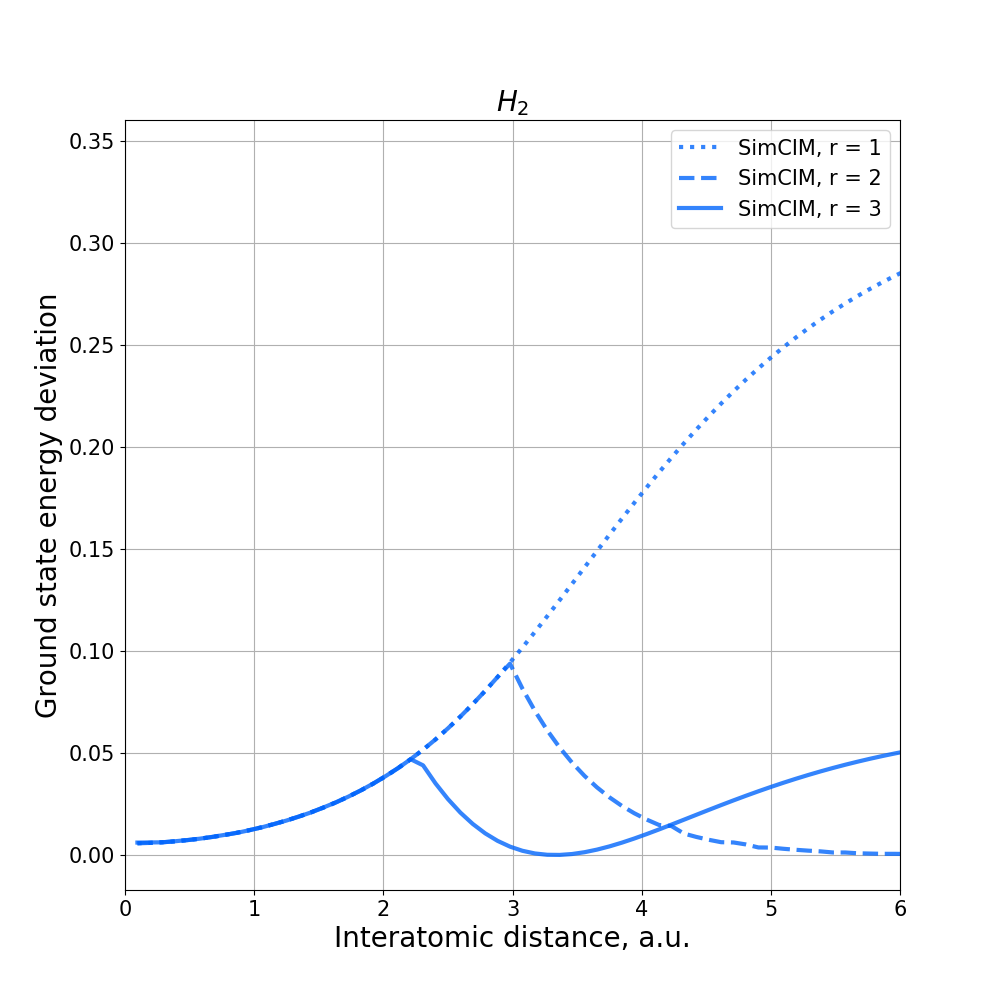

In [156]:
fig, ax = plt.subplots()
fig.set_figwidth(figsize)
fig.set_figheight(figsize)
ax.grid()
    
for r_num in r_nums:
    for method in methods:
        if method != 'exact':
            ax.plot(outputs_x[method][r_num] * angstrom_to_au,
                outputs_y[method][r_num] - outputs_y['exact'][r_num],
                label=method_to_label[method] + f', r = {r_num}',
                linewidth=method_to_linewidth[method],
                linestyle=r_num_to_linestyle[r_num],
                #linestyle='',
                #marker='o',
                #ms=method_to_ms[method],
                color=method_to_color[method],
                alpha=0.8)
            filename = f'hydrogen_difference_{method}_{r_num}'
            x_y_data = np.asarray([outputs_x[method][r_num] * angstrom_to_au,
                                   outputs_y[method][r_num] - outputs_y['exact'][r_num]])
            np.savetxt(filename, x_y_data)
    
# ax.plot(outputs_x['exact'][r_num] * angstrom_to_au,
#                 outputs_y['exact'][r_num],
#                 label=method_to_label['exact'],
#                 linewidth=method_to_linewidth[method],
#                 linestyle='-',
#                 #linestyle='',
#                 #marker='o',
#                 #ms=method_to_ms['exact'],
#                 color=method_to_color['exact'],
#                 alpha=0.9)
# method='exact'
# filename = f'{molecule_name}_{method}'
# x_y_data = np.asarray([outputs_x[method][1] * angstrom_to_au,
#                        outputs_y[method][1]])
# np.savetxt(filename, x_y_data)

ax.set_title(molecule_name_to_title.get(molecule_name_to_molecule[molecule_name], None), fontsize=fs)
ax.legend(loc='best', fontsize=fs-5)
ax.set_xlabel('Interatomic distance, a.u.', fontsize=fs)
for tick in ax.xaxis.get_major_ticks():
    tick.label.set_fontsize(fs-5) 
ax.set_ylabel('Ground state energy deviation', fontsize=fs)
for tick in ax.yaxis.get_major_ticks():
    tick.label.set_fontsize(fs-5) 

ax.set_xlim(molecule_name_to_xlim.get(molecule_name_to_molecule[molecule_name], (None, None)))
# ax.set_ylim(molecule_name_to_ylim.get(molecule_name_to_molecule[molecule_name], (None, None)))
fig.savefig('diff.svg')


In [183]:
prefix_for_files = os.path.join('../solutions', 'LiH_detailed_2')